In [1]:
import sys
from pathlib import Path

CODE_ROOT = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline")
for folder in ["", "scripts", "pre_processing", "feature_extraction", "post_processing"]:
    if str(CODE_ROOT / folder) not in sys.path:
        sys.path.insert(0, str(CODE_ROOT / folder))

import os
import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd

from scripts import *
from visualize import *
from registration import *


In [2]:
import yaml
config_path = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/config_files/setup.yaml")

with open(config_path, "r") as f:
    config = yaml.safe_load(f)

config

{'DATA_ROOT': '/Users/kamleshranabhat/Desktop/radiomics/dataset',
 'IMAGES_DIR': '/Users/kamleshranabhat/Desktop/radiomics/dataset/imagesTr',
 'LABELS_DIR': '/Users/kamleshranabhat/Desktop/radiomics/dataset/labelTr',
 'PROJECT_ROOT': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline',
 'CODEBASE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline',
 'OUTPUT_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs',
 'MASK_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/masks',
 'FEATURE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/features',
 'TABLE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/tables',
 'FIGURE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures',
 'REGISTRATION_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/registration',
 'BIAS_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/bias_correction',
 'REP

Channel 0 of BreastMRI018 is rotated by (3°, −2°, 2°) and shifted by (4, −3, 2) mm with a known transform
$T_{true}$ to create an artificial "moving" image. Registration must then find $T_{true}^{-1}$
(see the docstring of `register_rigid` for the direction). The error is measured at the ROI voxels.

In [3]:
case = "BreastMRI018"
fixed = load_image(image_path(case, 0), sitk.sitkFloat32)
mask_for_metric = registration_mask(case)
points = roi_points(load_image(label_path(case)) > 0)

true_transform = sitk.Euler3DTransform()
center = fixed.TransformContinuousIndexToPhysicalPoint((np.array(fixed.GetSize()) / 2.0).tolist())
true_transform.SetCenter(center)
true_transform.SetRotation(np.radians(3), np.radians(-2), np.radians(2))
true_transform.SetTranslation((4.0, -3.0, 2.0))
synthetic_moving = sitk.Resample(fixed, fixed, true_transform, sitk.sitkBSpline, 0.0)

found, info = register_rigid(fixed, synthetic_moving, mask_for_metric)
initial_error = displacement_mm(true_transform.GetInverse(), points)            # misalignment to undo
final_error = displacement_mm(found, points, true_transform.GetInverse())       # what is left after registration
print("misalignment before registration: mean %.2f mm, max %.2f mm" % (initial_error.mean(), initial_error.max()))
print("error after registration        : mean %.3f mm, max %.3f mm" % (final_error.mean(), final_error.max()))
print("MI metric before %.3f -> after %.3f   (more negative = better)" % (info["metric_before"], info["metric_after"]))
print("time %.1f s | %s" % (info["seconds"], info["stop_condition"][:90]))

misalignment before registration: mean 7.22 mm, max 10.69 mm
error after registration        : mean 0.006 mm, max 0.013 mm
MI metric before -0.047 -> after -1.141   (more negative = better)
time 7.0 s | RegularStepGradientDescentOptimizerv4: Step too small after 13 iterations. Current step (0


The registration recovers a 7 mm misalignment to within a few hundredths of a millimetre, so it is
suitable for measuring real inter-channel motion.

As a second check, registering an image to itself must give (almost) no displacement. Whatever it gives
is the **noise floor** of the method (from random sampling and optimizer tolerance).

In [4]:
self_transform, _ = register_rigid(fixed, fixed, mask_for_metric, seed=7)
print("self-registration: mean ROI displacement %.3f mm" % displacement_mm(self_transform, points).mean())

self-registration: mean ROI displacement 0.009 mm


Every channel 1–3 is registered to channel 0 of the same patient (15 registrations). For each, the table
reports the mutual information before/after, the rigid parameters and the displacement of the ROI voxels.

In [5]:
rows = []
transforms = {}
for case in list_case():
    fixed = load_image(image_path(case, 0), sitk.sitkFloat32)
    metric_mask = registration_mask(case)
    points = roi_points(load_image(label_path(case)) > 0)
    for channel in range(1, int(config["N_CHANNELS"])):
        moving = load_image(image_path(case, channel), sitk.sitkFloat32)
        transform, info = register_rigid(fixed, moving, metric_mask)
        transforms[(case, channel)] = transform
        sitk.WriteTransform(transform, str(Path(config["REGISTRATION_DIR"]) / f"{case}_ch{channel}_to_ch0.tfm"))

        d = displacement_mm(transform, points)
        rows.append({"case": case, "channel": channel,
                     "MI_before": info["metric_before"], "MI_after": info["metric_after"],
                     **euler_parameters(transform),
                     "roi_disp_mean_mm": d.mean(), "roi_disp_max_mm": d.max(),
                     "seconds": info["seconds"]})
motion = pd.DataFrame(rows)
motion.to_csv(Path(config["TABLE_DIR"]) / "registration_motion.csv", index=False)
display(motion.round(3))

,case,channel,MI_before,MI_after,rot_x_deg,rot_y_deg,rot_z_deg,tx_mm,ty_mm,tz_mm,roi_disp_mean_mm,roi_disp_max_mm,seconds
0,BreastMRI002,1,-0.715,-0.985,0.055,0.111,0.001,0.443,0.371,-0.169,0.630,0.730,5.204
1,BreastMRI002,2,-0.516,-0.856,0.058,0.208,-0.034,0.873,0.726,-0.297,1.179,1.423,5.616
2,BreastMRI002,3,-0.927,-1.128,0.042,0.092,0.082,0.258,0.031,-0.090,0.380,0.519,5.832
3,BreastMRI006,1,-0.383,-0.677,0.019,-0.092,0.227,-0.403,-0.212,-1.086,1.209,1.498,5.582
4,BreastMRI006,2,-0.787,-0.947,0.032,0.077,0.094,0.118,0.054,-0.019,0.316,0.470,5.599
5,BreastMRI006,3,-0.928,-1.064,0.114,0.044,0.028,0.033,0.162,0.192,0.204,0.324,5.642
6,BreastMRI018,1,-0.592,-0.694,-0.001,-0.052,0.035,-0.089,0.065,-0.111,0.160,0.236,6.561
7,BreastMRI018,2,-0.551,-0.648,-0.094,0.050,-0.074,0.168,0.254,-0.077,0.277,0.496,6.289
8,BreastMRI018,3,-0.280,-0.400,-0.088,0.266,-0.158,0.715,0.207,0.198,0.738,1.247,5.774
9,BreastMRI021,1,-0.383,-0.638,-0.070,0.106,0.151,0.052,1.157,-0.478,1.255,1.798,7.310


Registration always returns *some* transform. Before acting on these numbers we check that they are real
motion and not an artefact of matching two different contrasts:

1. **Stability.** Every pair with ≥ 1 mm displacement is registered again with a different random seed,
   a different sampling percentage and a larger metric region. A real shift is found every time; an
   artefact would change with the settings.
2. **An independent landmark.** The skin–air boundary is bright-to-dark in every channel, whatever the
   contrast. For many anterior–posterior intensity profiles through the breast, the position of the
   skin edge (most anterior voxel brighter than half the 99th percentile) is found in channel 0, in the
   stored channel k and in the registered channel k. The offset from channel 0 should shrink after
   registration if the motion is real.

In [6]:
stability_rows = []
settings = [{"seed": 1, "sampling_percentage": 0.05, "dilation": 5},
            {"seed": 2, "sampling_percentage": 0.10, "dilation": 5},
            {"seed": 3, "sampling_percentage": 0.05, "dilation": 15},
            {"seed": 4, "sampling_percentage": 0.02, "dilation": 5}]
moving_pairs = motion[motion["roi_disp_mean_mm"] >= 1.0][["case", "channel"]].itertuples(index=False)
for case, channel in moving_pairs:
    fixed = load_image(image_path(case, 0), sitk.sitkFloat32)
    moving = load_image(image_path(case, channel), sitk.sitkFloat32)
    points = roi_points(load_image(label_path(case)) > 0)
    displacements = []
    for s in settings:
        t, _ = register_rigid(fixed, moving, registration_mask(case, s["dilation"]),
                              sampling_percentage=s["sampling_percentage"], seed=s["seed"])
        displacements.append(displacement_mm(t, points).mean())
    stability_rows.append({"case": case, "channel": channel,
                           "first_run_mm": float(motion.query("case == @case and channel == @channel")["roi_disp_mean_mm"].iloc[0]),
                           "repeat_min_mm": min(displacements), "repeat_max_mm": max(displacements)})
stability = pd.DataFrame(stability_rows)
display(stability.round(2))

,case,channel,first_run_mm,repeat_min_mm,repeat_max_mm
0,BreastMRI002,2,1.18,1.06,1.17
1,BreastMRI006,1,1.21,1.19,1.21
2,BreastMRI021,1,1.26,1.25,1.26
3,BreastMRI021,2,5.52,5.01,5.61
4,BreastMRI021,3,1.28,1.27,1.28
5,BreastMRI023,1,1.28,1.14,1.29
6,BreastMRI023,2,1.38,1.24,1.39
7,BreastMRI023,3,1.27,1.14,1.28


In [7]:
def skin_edge_y(array_zyx, columns, threshold):
    """For each (z, x) column: largest y index (y grows towards anterior) with intensity > threshold."""
    positions = []
    for z, x in columns:
        above = np.nonzero(array_zyx[z, :, x] > threshold)[0]
        positions.append(above.max() if above.size else np.nan)
    return np.array(positions, dtype=float)


rows = []
for (case, channel), transform in transforms.items():
    fixed = load_image(image_path(case, 0), sitk.sitkFloat32)
    moving = load_image(image_path(case, channel), sitk.sitkFloat32)
    registered = apply_transform(moving, fixed, transform)
    label_arr = array_from_image(load_image(label_path(case))) > 0
    z_idx, _, x_idx = np.nonzero(label_arr)
    columns = sorted(set(zip(z_idx[::200], x_idx[::200])))           # profiles through the breasts
    arrays = {"ch0": array_from_image(fixed), "stored": array_from_image(moving),
              "registered": array_from_image(registered)}
    edges = {k: skin_edge_y(a, columns, 0.5 * np.percentile(a, 99)) for k, a in arrays.items()}
    sy = fixed.GetSpacing()[1]
    rows.append({"case": case, "channel": channel,
                 "skin_offset_stored_mm": np.nanmedian(np.abs(edges["stored"] - edges["ch0"])) * sy,
                 "skin_offset_registered_mm": np.nanmedian(np.abs(edges["registered"] - edges["ch0"])) * sy,
                 "roi_disp_mean_mm": float(motion.query("case == @case and channel == @channel")["roi_disp_mean_mm"].iloc[0])})
skin = pd.DataFrame(rows)
display(skin.round(2))

,case,channel,skin_offset_stored_mm,skin_offset_registered_mm,roi_disp_mean_mm
0,BreastMRI002,1,0.59,0.59,0.63
1,BreastMRI002,2,1.17,0.59,1.18
2,BreastMRI002,3,0.00,0.00,0.38
3,BreastMRI006,1,0.68,0.00,1.21
4,BreastMRI006,2,0.00,0.00,0.32
5,BreastMRI006,3,0.00,0.00,0.20
6,BreastMRI018,1,0.00,0.00,0.16
7,BreastMRI018,2,0.67,0.00,0.28
8,BreastMRI018,3,0.00,0.00,0.74
9,BreastMRI021,1,1.48,0.74,1.26


In [8]:
threshold_mm = 1.0
worst = motion.loc[motion["roi_disp_mean_mm"].idxmax()]
print("largest mean ROI displacement: %.2f mm (%s ch%d), largest single-voxel displacement: %.2f mm"
      % (worst["roi_disp_mean_mm"], worst["case"], worst["channel"], motion["roi_disp_max_mm"].max()))
print("channel pairs with mean displacement >= %.1f mm: %d of %d"
      % (threshold_mm, (motion["roi_disp_mean_mm"] >= threshold_mm).sum(), len(motion)))
print("repeat registrations agree within %.2f mm" % (stability["repeat_max_mm"] - stability["repeat_min_mm"]).max())
needed = bool((motion["roi_disp_mean_mm"] >= threshold_mm).any())
print("registration required:", needed, "| config[\"PIPELINE_OPTIONS\"][\"registration\"] =", config["PIPELINE_OPTIONS"]["registration"])

largest mean ROI displacement: 5.52 mm (BreastMRI021 ch2), largest single-voxel displacement: 9.19 mm
channel pairs with mean displacement >= 1.0 mm: 8 of 15
repeat registrations agree within 0.60 mm
registration required: True | config["PIPELINE_OPTIONS"]["registration"] = True


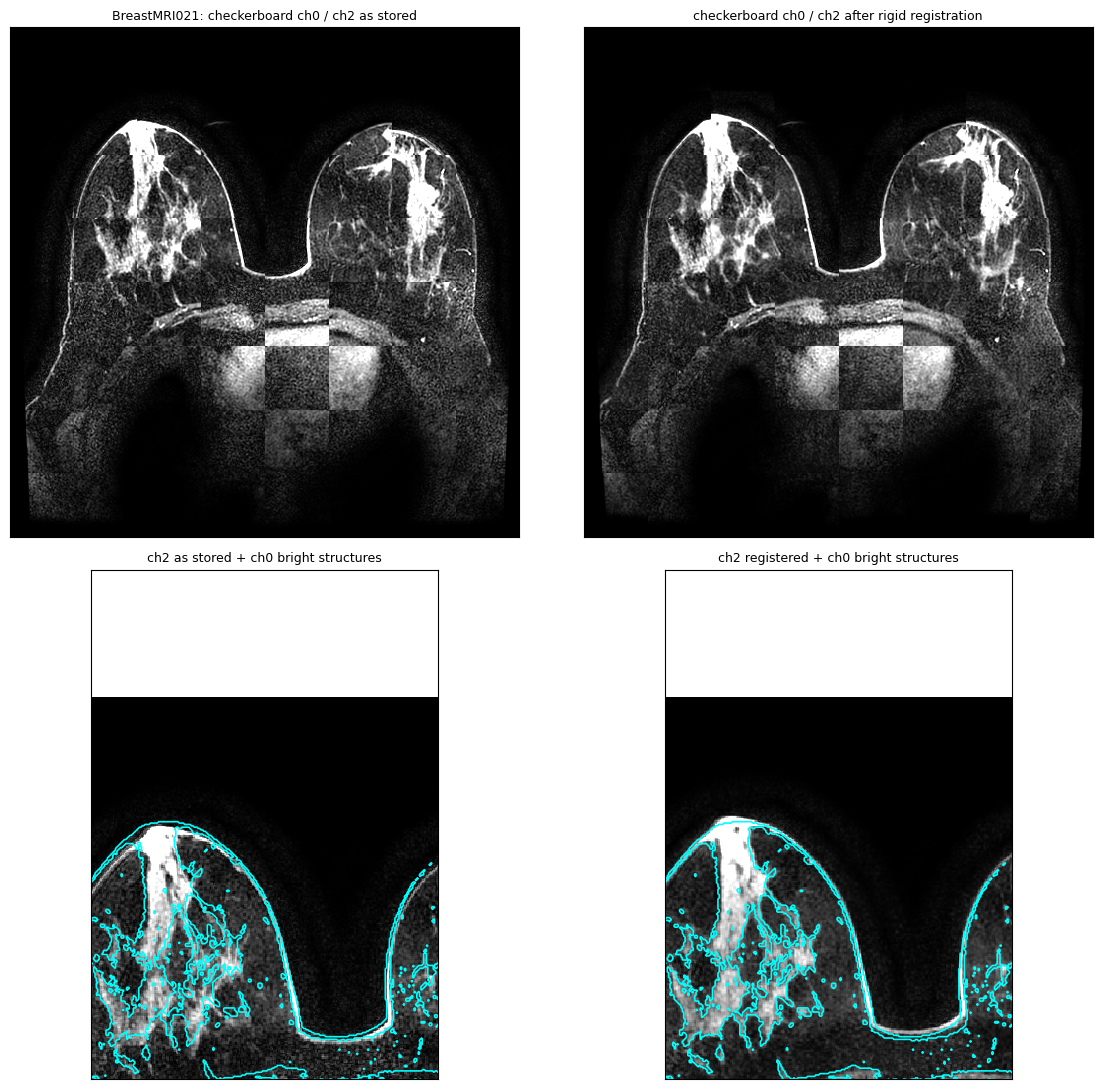

In [9]:
case, channel = worst["case"], int(worst["channel"])
fixed = load_image(image_path(case, 0), sitk.sitkFloat32)
moving = load_image(image_path(case, channel), sitk.sitkFloat32)
registered = apply_transform(moving, fixed, transforms[(case, channel)])
label_arr = array_from_image(load_image(label_path(case))) > 0
z = largest_slice_index(label_arr, 0)
sp = spacing_zyx(fixed)

ch0 = array_from_image(fixed)
ch0_structures = ch0 > 0.5 * np.percentile(ch0, 99)          # bright skin line + dense tissue of channel 0

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
show_image_with_mask(axes[0, 0], array_from_image(checkerboard(fixed, moving)), None, sp, 0, z,
                     title=f"{case}: checkerboard ch0 / ch{channel} as stored", window=(0, 1))
show_image_with_mask(axes[0, 1], array_from_image(checkerboard(fixed, registered)), None, sp, 0, z,
                     title=f"checkerboard ch0 / ch{channel} after rigid registration", window=(0, 1))
show_image_with_mask(axes[1, 0], array_from_image(moving), ch0_structures, sp, 0, z, color="cyan",
                     title=f"ch{channel} as stored + ch0 bright structures")
show_image_with_mask(axes[1, 1], array_from_image(registered), ch0_structures, sp, 0, z, color="cyan",
                     title=f"ch{channel} registered + ch0 bright structures")
# zoom the bottom row onto the patient's right breast (viewer's left)
plane = radiological_view(label_arr, 0, z)
rows_idx, cols_idx = np.nonzero(plane)
left_half = cols_idx < plane.shape[1] // 2
r0, r1 = rows_idx[left_half].min() - 25, rows_idx[left_half].max() + 35
c0, c1 = cols_idx[left_half].min() - 25, cols_idx[left_half].max() + 25
for ax in axes[1]:
    ax.set_xlim(c0, c1); ax.set_ylim(r0, r1)
fig.tight_layout()
fig.savefig(Path(config["FIGURE_DIR"]) / "registration_check.png", dpi=110)
plt.show()

In [10]:
case, channel = "BreastMRI021", 2
reloaded = load_registration_transform(case, channel)
print("parameters identical after reload:",
      np.allclose(reloaded.GetParameters(), transforms[(case, channel)].GetParameters()))
registered = load_registered_channel(case, channel)
print("registered image:", registered.GetSize(), registered.GetPixelIDTypeAsString(),
      "| same grid as ch0:", registered.GetSize() == load_image(image_path(case, 0)).GetSize())

parameters identical after reload: True
registered image: (512, 512, 176) 32-bit float | same grid as ch0: True
